# Visualización de datos: el catálogo de Netflix, 2008-2021

**Asignatura:** Visualización de Datos  
**Entregable:** notebook ejecutable con las cuatro visualizaciones del Paso 2 y su interpretación técnica.

Este notebook analiza el catálogo de Netflix con cuatro herramientas distintas: un treemap para la jerarquía, un grafo de co-ocurrencias para las relaciones, un panel histograma + boxplot para las distribuciones y una serie de tiempo interactiva. Cada gráfico va seguido de una celda de interpretación donde se explica qué canal visual codifica cada variable y por qué se eligió así.

Para ejecutarlo solo hacen falta `pandas`, `numpy`, `scipy`, `matplotlib`, `seaborn`, `plotly`, `networkx` y `squarify` (ver `requirements.txt`). Los datos se descargan solos desde GitHub; si no hay conexión se usa el CSV incluido en el repositorio.

## Paso 1. Selección del dataset

**Dataset:** *Netflix Movies and TV Shows*, publicado originalmente en Kaggle y redistribuido en el repositorio TidyTuesday (semana del 20 de abril de 2021). Licencia abierta, descarga sin registro.

**Qué contiene:** 7,787 títulos y 12 columnas (`show_id`, `type`, `title`, `director`, `cast`, `country`, `date_added`, `release_year`, `rating`, `duration`, `listed_in`, `description`). Es una foto del catálogo estadounidense hasta el 16 de enero de 2021.

Elegí este dataset porque cumple los cuatro requisitos con columnas que ya existen, sin tener que fabricar datos:

| Requisito | Cómo se cumple |
|---|---|
| Categórica con jerarquía | `type` (película o serie) contiene a `rating` (público) y este a `listed_in` (género). |
| Conexiones o co-ocurrencias | `cast` lista los actores de cada título. Dos actores están conectados si comparten título. |
| Cuantitativas continuas y discretas | `duration` en minutos (continua), años de rezago entre estreno y llegada a Netflix (discreta), `release_year`. |
| Índice temporal | `date_added` permite agrupar por mes. |

Una limitación que conviene tener presente desde el inicio: el catálogo es la lista de títulos disponibles al momento de la captura. Lo que Netflix retiró antes de 2021 no aparece, así que los conteos de años anteriores probablemente subestiman lo que realmente se añadió.

In [1]:
# =====================================================================
# 0. Configuración del entorno
# =====================================================================
# En Google Colab basta con descomentar la siguiente línea:
# !pip install -q plotly networkx seaborn squarify

import itertools
import os
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import squarify                      # solo para las versiones estáticas del informe PDF
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")

# Carpeta donde se guardan las figuras (HTML interactivo y PNG estático)
os.makedirs("figuras", exist_ok=True)

In [2]:
# =====================================================================
# 1. Carga del dataset
# =====================================================================
# Fuente: "Netflix Movies and TV Shows" (TidyTuesday, 20-abr-2021, tomado de Kaggle).
# Se lee directo desde GitHub; si no hay internet se usa la copia local del repositorio.
URL = ("https://raw.githubusercontent.com/rfordatascience/tidytuesday/"
       "master/data/2021/2021-04-20/netflix_titles.csv")
try:
    df = pd.read_csv(URL)
    print("Dataset leído desde GitHub.")
except Exception as err:
    print("No se pudo leer la URL (", err, "). Se usa la copia local.")
    df = pd.read_csv("netflix_titles.csv")

print("Dimensiones:", df.shape)
df.head(3)

Dataset leído desde GitHub.
Dimensiones: (7787, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."


In [3]:
# =====================================================================
# 2. Limpieza y variables derivadas
# =====================================================================
# 2.1 Fecha de incorporación al catálogo (viene como texto: "August 14, 2020")
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%B %d, %Y", errors="coerce")
df["year_added"] = df["date_added"].dt.year

# 2.2 Duración: en películas son minutos, en series son temporadas.
df["duration_num"] = df["duration"].str.extract(r"(\d+)").astype(float)
df["minutos"] = np.where(df["type"] == "Movie", df["duration_num"], np.nan)
df["temporadas"] = np.where(df["type"] == "TV Show", df["duration_num"], np.nan)

# 2.3 Rezago: años entre el estreno original y la llegada a Netflix.
#     Hay 12 casos negativos (estrenos anunciados antes de publicarse): se fijan en 0.
df["rezago"] = (df["year_added"] - df["release_year"]).clip(lower=0)

# 2.4 Jerarquía: clasificación por edades agrupada en 4 públicos (nivel intermedio del treemap)
publico = {
    "TV-MA": "Adultos", "R": "Adultos", "NC-17": "Adultos", "NR": "Adultos", "UR": "Adultos",
    "TV-14": "Adolescentes", "PG-13": "Adolescentes",
    "TV-PG": "Familiar", "PG": "Familiar", "TV-G": "Familiar", "G": "Familiar",
    "TV-Y7": "Niños", "TV-Y7-FV": "Niños", "TV-Y": "Niños",
}
df["publico"] = df["rating"].map(publico).fillna("Sin clasificar")

# 2.5 Género principal = primero de la lista "listed_in"; los poco frecuentes pasan a "Otros"
df["genero_principal"] = df["listed_in"].str.split(",").str[0].str.strip()
top_generos = df["genero_principal"].value_counts().head(8).index
df["genero_tm"] = df["genero_principal"].where(df["genero_principal"].isin(top_generos), "Otros")

# 2.6 País principal (primero de la lista)
df["pais_principal"] = df["country"].str.split(",").str[0].str.strip()

print("Valores nulos relevantes:")
print(df[["date_added", "rating", "cast", "country"]].isna().sum())

Valores nulos relevantes:
date_added     10
rating          7
cast          718
country       507
dtype: int64


In [4]:
# =====================================================================
# 3. Verificación de los cuatro requisitos del dataset
# =====================================================================
n_generos = len(set(g.strip() for l in df["listed_in"] for g in l.split(",")))
n_actores = len(set(a.strip() for l in df["cast"].dropna().str.split(", ") for a in l))
requisitos = pd.DataFrame({
    "Requisito": ["Categórica con jerarquía", "Conexiones / co-ocurrencias",
                  "Cuantitativas continuas y discretas", "Índice temporal"],
    "Columnas usadas": ["type > publico (rating) > genero_principal",
                        "cast (actores que aparecen juntos en un título)",
                        "minutos (continua), rezago (discreta), release_year",
                        "date_added (mensual, 2015-2020)"],
    "Evidencia": [f"2 tipos > 4 públicos > {len(top_generos) + 1} géneros",
                  f"{n_actores:,} actores distintos",
                  f"{df['minutos'].notna().sum():,} películas con duración",
                  f"{df['date_added'].min():%Y-%m-%d} a {df['date_added'].max():%Y-%m-%d}"],
})
requisitos

,Requisito,Columnas usadas,Evidencia
0,Categórica con jerarquía,type > publico (rating) > genero_principal,2 tipos > 4 públicos > 9 géneros
1,Conexiones / co-ocurrencias,cast (actores que aparecen juntos en un título),"32,881 actores distintos"
2,Cuantitativas continuas y discretas,"minutos (continua), rezago (discreta), release...","5,377 películas con duración"
3,Índice temporal,"date_added (mensual, 2015-2020)",2008-01-01 a 2021-01-16


## Paso 2.1. Jerarquía y composición: treemap

**Pregunta:** ¿cómo se reparte el catálogo entre películas y series, entre públicos y entre géneros, y qué tan reciente es cada porción?

**Codificación visual.** El área es la cantidad de títulos y el color es el año de estreno promedio de cada bloque. Los tres niveles (tipo, público, género) se leen de afuera hacia adentro.

**Control del aspect ratio y legibilidad.** Varias decisiones del código responden a este punto:

1. **Lienzo de 1100 x 680 px** (relación 1.62:1). Un lienzo apaisado deja espacio para los textos y mantiene los bloques grandes sin deformarse.
2. **Empaquetado `squarify` con `squarifyratio=1`.** El algoritmo intenta que cada rectángulo se parezca a un cuadrado. Esto importa porque el ojo estima mal las áreas (Cleveland y McGill las ubican por debajo de la posición y la longitud), y la estimación empeora cuando los rectángulos son alargados y delgados.
3. **Solo 8 géneros más "Otros".** Sin esta agrupación habría decenas de bloques minúsculos con texto imposible de leer. "Otros" reúne 1,937 títulos (24.9%), un costo que acepto a cambio de legibilidad.
4. **`pad=3` y `cornerradius`.** Separan visualmente los bloques para que los bordes no se fundan.
5. **`uniformtext(minsize=10, mode="hide")`.** Si una etiqueta no cabe a tamaño legible, se oculta en lugar de superponerse. El detalle sigue disponible al pasar el cursor.
6. **Escala secuencial `Viridis` invertida**, perceptualmente uniforme y apta para daltonismo, con rango ajustado a los datos (2001 a 2018) para no desperdiciar contraste.

El área de un treemap se compara con menos precisión que la longitud de una barra. Aquí lo acepto porque lo que interesa es la composición anidada y no la comparación exacta entre dos bloques.

In [5]:
# =====================================================================
# 4. JERARQUÍA Y COMPOSICIÓN: treemap con Plotly Express
# =====================================================================
# Agregamos a nivel de hoja (tipo, público, género): conteo y año de estreno promedio
tm = (df.groupby(["type", "publico", "genero_tm"])
        .agg(titulos=("show_id", "count"), anio_prom=("release_year", "mean"))
        .reset_index())

ANCHO, ALTO = 1100, 680            # relación 1.62:1, cercana a la proporción áurea

fig_tm = px.treemap(
    tm,
    path=[px.Constant("Catálogo"), "type", "publico", "genero_tm"],  # raíz > tipo > público > género
    values="titulos",                 # el ÁREA codifica la cantidad de títulos
    color="anio_prom",                # el COLOR codifica el año de estreno promedio
    color_continuous_scale="Viridis_r",
    range_color=[tm["anio_prom"].min(), tm["anio_prom"].max()],
    width=ANCHO, height=ALTO,
)
fig_tm.update_traces(
    # algoritmo squarify: minimiza la diferencia entre ancho y alto de cada rectángulo
    tiling=dict(packing="squarify", squarifyratio=1, pad=3),
    texttemplate="%{label}<br>%{value:,} (%{percentParent:.0%})",
    hovertemplate="<b>%{label}</b><br>Títulos: %{value:,}<br>Año promedio: %{color:.1f}<extra></extra>",
    marker=dict(cornerradius=3),
    textfont=dict(size=13),
)
fig_tm.update_layout(
    title="Catálogo de Netflix por tipo, público y género principal",
    margin=dict(t=60, l=10, r=10, b=10),
    uniformtext=dict(minsize=10, mode="hide"),   # oculta etiquetas que no caben en vez de solaparlas
    coloraxis_colorbar=dict(title="Año de<br>estreno<br>promedio"),
)
fig_tm.write_html("figuras/01_treemap.html")
fig_tm.show()

In [6]:
# Cifras de apoyo para la interpretación
tot = tm["titulos"].sum()
print("Participación por tipo:")
print((tm.groupby("type")["titulos"].sum() / tot).round(3).to_string())
print("\nParticipación por público dentro de cada tipo:")
print(pd.crosstab(df["type"], df["publico"], normalize="index").round(3).to_string())
print("\nTop 6 hojas:")
print(tm.sort_values("titulos", ascending=False).head(6).round(1).to_string(index=False))
print("\nAño de estreno promedio por tipo:")
print(df.groupby("type")["release_year"].mean().round(1).to_string())

Participación por tipo:
type
Movie      0.691
TV Show    0.309

Participación por público dentro de cada tipo:
publico  Adolescentes  Adultos  Familiar  Niños  Sin clasificar
type                                                           
Movie           0.308    0.483     0.168  0.040           0.001
TV Show         0.273    0.425     0.159  0.141           0.001

Top 6 hojas:
   type      publico genero_tm  titulos  anio_prom
  Movie      Adultos    Dramas      773     2014.9
  Movie      Adultos     Otros      644     2013.1
  Movie      Adultos  Comedies      490     2014.7
  Movie Adolescentes    Dramas      464     2012.4
  Movie Adolescentes  Comedies      461     2011.6
TV Show      Adultos     Otros      428     2017.4

Año de estreno promedio por tipo:
type
Movie      2012.9
TV Show    2016.2


### Interpretación del treemap

**Composición.** Las películas son el 69.1% del catálogo (5,377) y las series el 30.9% (2,410). El bloque individual más grande es *Películas > Adultos > Dramas*, con 773 títulos, el 9.9% del total.

**Públicos.** El contenido para adultos domina en ambos formatos, pero con matices: 48.3% de las películas frente a 42.5% de las series. La diferencia grande está en el público infantil, que pesa 14.1% en series y solo 4.0% en películas. Entre las series infantiles destaca *Kids' TV*, con 290 títulos.

**Color y antigüedad.** El color separa los dos mundos con claridad. Los bloques de series son casi todos violeta oscuro, es decir, estrenos recientes (el bloque de *Crime TV Shows* promedia 2017.9 y el de *Otros* en series para adultos, 2017.4). Las películas se reparten entre azules y verdes: los bloques grandes promedian entre 2011 y 2015, y *Action & Adventure* para adolescentes (305 títulos) baja hasta 2008.2. Los bloques amarillos, en el rincón de películas familiares (*Action & Adventure* con 52 títulos y promedio 2001.4, y *Otros* con 72 y 2003.3), son el material más antiguo del catálogo. El año promedio general es 2012.9 para películas y 2016.2 para series.

**Lectura crítica.** Lo que el gráfico no permite ver bien son diferencias pequeñas de área: distinguir *Comedies* (490) de *Action & Adventure* (363) dentro de adultos exige leer el número. Tampoco muestra dispersión, porque un promedio de 2013 puede ser un bloque homogéneo o una mezcla de estrenos de 1990 y de 2020. Esa pregunta se responde con los histogramas de la sección 2.3.

## Paso 2.2. Relaciones y redes: co-ocurrencia de actores

**Pregunta:** ¿qué grupos de actores trabajan repetidamente juntos en el catálogo?

**Construcción del grafo.** Cada nodo es un actor. Dos actores se unen con una arista cuyo peso es el número de títulos que comparten. El grafo completo tiene 32,489 nodos y 252,053 aristas, y dibujado tal cual es una mancha gris.

**Estrategia aplicada contra la "bola de pelos" (hairball).** El código aplica seis medidas en cadena, y cada una reduce un tipo distinto de ruido:

1. **Filtrado de aristas por peso mínimo.** Se conservan solo las parejas que coinciden en 3 o más títulos (`PESO_MIN = 3`). Casi todas las aristas del grafo completo son coincidencias de un solo título, que no indican colaboración sostenida.
2. **Selección de las 6 componentes conexas mayores.** Elimina las parejas y tríos aislados que ocupan espacio sin aportar estructura.
3. **Detección de comunidades por modularidad** (`greedy_modularity_communities`) y color por comunidad. El color agrupa visualmente, así que el ojo no necesita seguir cada arista.
4. **Tamaño de nodo proporcional al grado** y etiquetas solo para el actor más conectado de cada comunidad. Rotular los 346 nombres volvería ilegible el gráfico.
5. **Aristas en tres capas** de grosor y opacidad según su peso (3 títulos, 4 a 5, 6 o más). Las relaciones débiles quedan al fondo y las fuertes sobresalen.
6. **Layout Kamada-Kawai por componente**, colocadas en una cuadrícula. Calcular el layout en conjunto amontona todo en el centro; separarlas evita que las componentes se pisen.

La tabla siguiente muestra cuánto cae el tamaño y cuánto sube la densidad en cada paso.

In [7]:
# =====================================================================
# 5. RELACIONES Y REDES: co-ocurrencia de actores con NetworkX + Plotly
# =====================================================================
# 5.1 Conteo de apariciones y de pares de actores que comparten título
reparto = df["cast"].dropna().str.split(", ")
apariciones = Counter(a.strip() for l in reparto for a in set(l))
pares = Counter()
for l in reparto:
    for a, b in itertools.combinations(sorted(set(x.strip() for x in l)), 2):
        pares[(a, b)] += 1              # el peso de la arista = títulos en común

def construir_grafo(peso_min):
    """Grafo no dirigido con las parejas que coinciden en al menos `peso_min` títulos."""
    g = nx.Graph()
    g.add_weighted_edges_from((a, b, w) for (a, b), w in pares.items() if w >= peso_min)
    return g

In [8]:
# 5.2 ESTRATEGIA ANTI "BOLA DE PELOS" (hairball), aplicada paso a paso:
#   (1) Filtrado de aristas por peso: se descartan coincidencias casuales (1 o 2 títulos).
#   (2) Selección de componentes conexas grandes: se descartan pares y tríos aislados.
#   (3) Detección de comunidades (modularidad) y color por comunidad.
#   (4) Tamaño de nodo proporcional al grado y etiquetas solo para los nodos más conectados.
#   (5) Aristas en 3 capas de grosor/opacidad según su peso (las débiles quedan al fondo).
#   (6) Layout por componente (spring ponderado) y componentes ubicadas en una cuadrícula,
#       para que no se superpongan.
PESO_MIN = 3
N_COMPONENTES = 6

G_all = construir_grafo(1)
G2 = construir_grafo(2)
G3 = construir_grafo(PESO_MIN)
componentes = sorted(nx.connected_components(G3), key=len, reverse=True)[:N_COMPONENTES]
G = G3.subgraph(set().union(*componentes)).copy()

embudo = pd.DataFrame({
    "Etapa": ["Grafo completo (todas las parejas)", "Aristas con peso >= 2",
              f"Aristas con peso >= {PESO_MIN}", f"Las {N_COMPONENTES} mayores componentes"],
    "Nodos": [G_all.number_of_nodes(), G2.number_of_nodes(), G3.number_of_nodes(), G.number_of_nodes()],
    "Aristas": [G_all.number_of_edges(), G2.number_of_edges(), G3.number_of_edges(), G.number_of_edges()],
})
embudo["Densidad"] = [nx.density(g) for g in (G_all, G2, G3, G)]
embudo

,Etapa,Nodos,Aristas,Densidad
0,Grafo completo (todas las parejas),32489,252053,0.000478
1,Aristas con peso >= 2,3741,9143,0.001307
2,Aristas con peso >= 3,889,1956,0.004955
3,Las 6 mayores componentes,346,974,0.016319


In [9]:
# 5.3 Comunidades, grado y layout
comunidades = nx.community.greedy_modularity_communities(G, weight="weight")
com_de = {n: i for i, c in enumerate(comunidades) for n in c}
Q = nx.community.modularity(G, comunidades, weight="weight")
print(f"{len(comunidades)} comunidades, modularidad Q = {Q:.3f}")

def layout_por_componentes(g, columnas=3, hueco=2.8):
    """Layout Kamada-Kawai (reparte los nodos según la distancia en el grafo) calculado por
    separado en cada componente y colocado en una cuadrícula. La componente mayor recibe más espacio."""
    comps = sorted(nx.connected_components(g), key=len, reverse=True)
    n_max = len(comps[0])
    pos = {}
    for i, c in enumerate(comps):
        sub = g.subgraph(c)
        p = nx.kamada_kawai_layout(sub) if len(c) > 2 else nx.spring_layout(sub, seed=7)
        escala = 0.5 + 0.75 * np.sqrt(len(c) / n_max)
        fila, col = divmod(i, columnas)
        for n, (x, y) in p.items():
            pos[n] = (col * hueco + x * escala, -fila * hueco + y * escala)
    return pos

pos = layout_por_componentes(G)
grado = dict(G.degree())
fuerza = dict(G.degree(weight="weight"))
# Etiqueta solo para el actor más conectado de cada comunidad con 6 o más miembros
nombres_top = [max(c, key=grado.get) for c in comunidades if len(c) >= 6]

15 comunidades, modularidad Q = 0.842


In [10]:
# 5.4 Figura interactiva
paleta = px.colors.qualitative.Dark24

def trazo_aristas(rango, ancho, opacidad, nombre):
    xs, ys = [], []
    for u, v, w in G.edges(data="weight"):
        if rango[0] <= w <= rango[1]:
            xs += [pos[u][0], pos[v][0], None]
            ys += [pos[u][1], pos[v][1], None]
    return go.Scatter(x=xs, y=ys, mode="lines", name=nombre, hoverinfo="skip",
                      line=dict(width=ancho, color=f"rgba(90,90,90,{opacidad})"))

fig_g = go.Figure()
fig_g.add_trace(trazo_aristas((3, 3), 0.6, 0.20, "3 títulos juntos"))
fig_g.add_trace(trazo_aristas((4, 5), 1.4, 0.40, "4 a 5 títulos"))
fig_g.add_trace(trazo_aristas((6, 999), 2.6, 0.65, "6 o más títulos"))

nodos = list(G.nodes())
fig_g.add_trace(go.Scatter(
    x=[pos[n][0] for n in nodos], y=[pos[n][1] for n in nodos], mode="markers",
    name="Actores", showlegend=False,
    marker=dict(size=[6 + 1.3 * grado[n] for n in nodos],
                color=[paleta[com_de[n] % len(paleta)] for n in nodos],
                line=dict(width=0.8, color="white")),
    customdata=np.array([[apariciones[n], grado[n], com_de[n] + 1] for n in nodos]),
    text=nodos,
    hovertemplate=("<b>%{text}</b><br>Títulos: %{customdata[0]}"
                   "<br>Colaboradores: %{customdata[1]}<br>Comunidad %{customdata[2]}<extra></extra>"),
))
fig_g.add_trace(go.Scatter(
    x=[pos[n][0] for n in nombres_top], y=[pos[n][1] for n in nombres_top],
    mode="text", text=nombres_top, textposition="top center", hoverinfo="skip",
    textfont=dict(size=11, color="black"), showlegend=False))
fig_g.update_layout(
    title=f"Co-ocurrencia de actores (>= {PESO_MIN} títulos juntos), {len(G)} actores en {N_COMPONENTES} componentes",
    width=1100, height=720, plot_bgcolor="white",
    xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x"),
    legend=dict(title="Grosor de arista", orientation="h", y=-0.02),
    margin=dict(t=60, l=10, r=10, b=10),
)
fig_g.write_html("figuras/02_grafo_actores.html")
fig_g.show()

In [11]:
# Métricas para la interpretación
print("Componentes (nodos):", [len(c) for c in componentes])
for i, c in enumerate(componentes[:4]):
    sub = G.subgraph(c)
    top = sorted(sub.degree, key=lambda x: -x[1])[:3]
    pais = df[df["cast"].fillna("").apply(lambda s: any(n in s for n, _ in top[:1]))]["pais_principal"].mode()
    print(f"Componente {i+1}: {len(c)} nodos, {sub.number_of_edges()} aristas, "
          f"hubs: {[n for n, _ in top]}, país modal del hub: {pais.iloc[0] if len(pais) else 's/d'}")
cc = nx.betweenness_centrality(G, weight=None)
print("\nMayor intermediación:", sorted(cc, key=cc.get, reverse=True)[:5])

Componentes (nodos): [164, 89, 38, 21, 17, 17]
Componente 1: 164 nodos, 510 aristas, hubs: ['Takahiro Sakurai', 'Yuki Kaji', 'Daisuke Ono'], país modal del hub: Japan
Componente 2: 89 nodos, 135 aristas, hubs: ['Shah Rukh Khan', 'Anupam Kher', 'Akshay Kumar'], país modal del hub: India
Componente 3: 38 nodos, 136 aristas, hubs: ['Andrea Libman', 'Vincent Tong', 'Ian James Corlett'], país modal del hub: United States
Componente 4: 21 nodos, 68 aristas, hubs: ['Sean Astin', 'Brennan Murray', 'Erica Luttrell'], país modal del hub: United States

Mayor intermediación: ['Jun Fukuyama', 'Bryce Papenbrook', 'Takahiro Sakurai', 'Erin Fitzgerald', 'Stephanie Sheh']


### Interpretación del grafo

**Efecto de la estrategia.** Pasar de 252,053 aristas a 974 (y de 32,489 nodos a 346) deja un gráfico que se puede leer. La densidad sube de 0.0005 a 0.016, lo que refleja que se conservó la parte donde los actores efectivamente se repiten.

**Estructura.** La red se divide en varias islas. Las seis componentes tienen 164, 89, 38, 21, 17 y 17 actores, y la modularidad de la partición (Q = 0.842) es alta: los grupos están muy cerrados sobre sí mismos. Cada isla corresponde a un nicho reconocible:

- La mayor (164 actores) está dominada por actores de voz del anime japonés. Los de mayor grado son Takahiro Sakurai (37 colaboradores), Yuki Kaji (33) y Daisuke Ono (29).
- La segunda (89) es la de Bollywood, con Shah Rukh Khan y Anupam Kher (17 colaboradores cada uno) como núcleo.
- La tercera (38) reúne actores de voz de animación infantil, con Andrea Libman, Vincent Tong y Erin Mathews a la cabeza.

**Puentes.** La centralidad de intermediación señala a Jun Fukuyama, Bryce Papenbrook, Takahiro Sakurai, Erin Fitzgerald y Stephanie Sheh. Los nombres que reconozco de esa lista (Papenbrook, Fitzgerald, Sheh) son de doblaje al inglés de anime, lo que sugiere que conectan al elenco japonés con el doblado. El dataset no registra el idioma de la voz, así que esa lectura es una hipótesis y no un resultado.

**Principios de codificación.** El color (matiz) codifica una variable nominal, la comunidad, que es el uso correcto de un canal cualitativo. El tamaño codifica una cantidad (grado). El grosor y la opacidad de las aristas codifican el peso. La posición, en cambio, no tiene significado cuantitativo en un layout de fuerzas: solo importa la cercanía relativa, y no debe leerse un eje.

**Límites.** El filtro a 3 títulos descarta colaboraciones reales pero breves. Además, los actores se identifican por nombre escrito, de modo que un homónimo o una grafía distinta produce un nodo duplicado o fusionado.

## Paso 2.3. Distribuciones: histograma y boxplot combinados

**Pregunta:** ¿qué forma tienen las variables cuantitativas y dónde están sus valores extremos?

Se analizan dos variables con perfiles muy distintos:

- **Duración de las películas** en minutos (continua, 5,377 datos).
- **Rezago** en años entre el estreno original y la llegada a Netflix (discreta, 7,777 datos). Se calcula como `año de incorporación - release_year`, y los 12 casos negativos se fijan en 0.

El panel apila un histograma con curva KDE sobre un boxplot horizontal que comparte el eje x. Cada gráfico cubre lo que el otro oculta: el histograma muestra la forma completa (modas, joroba, cola), y el boxplot resume cuartiles y marca los atípicos con la regla de Tukey (fuera de Q1 - 1.5·IQR y Q3 + 1.5·IQR). Las líneas verticales de media (negra, discontinua) y mediana (roja) hacen visible la asimetría sin necesidad de leer la tabla.

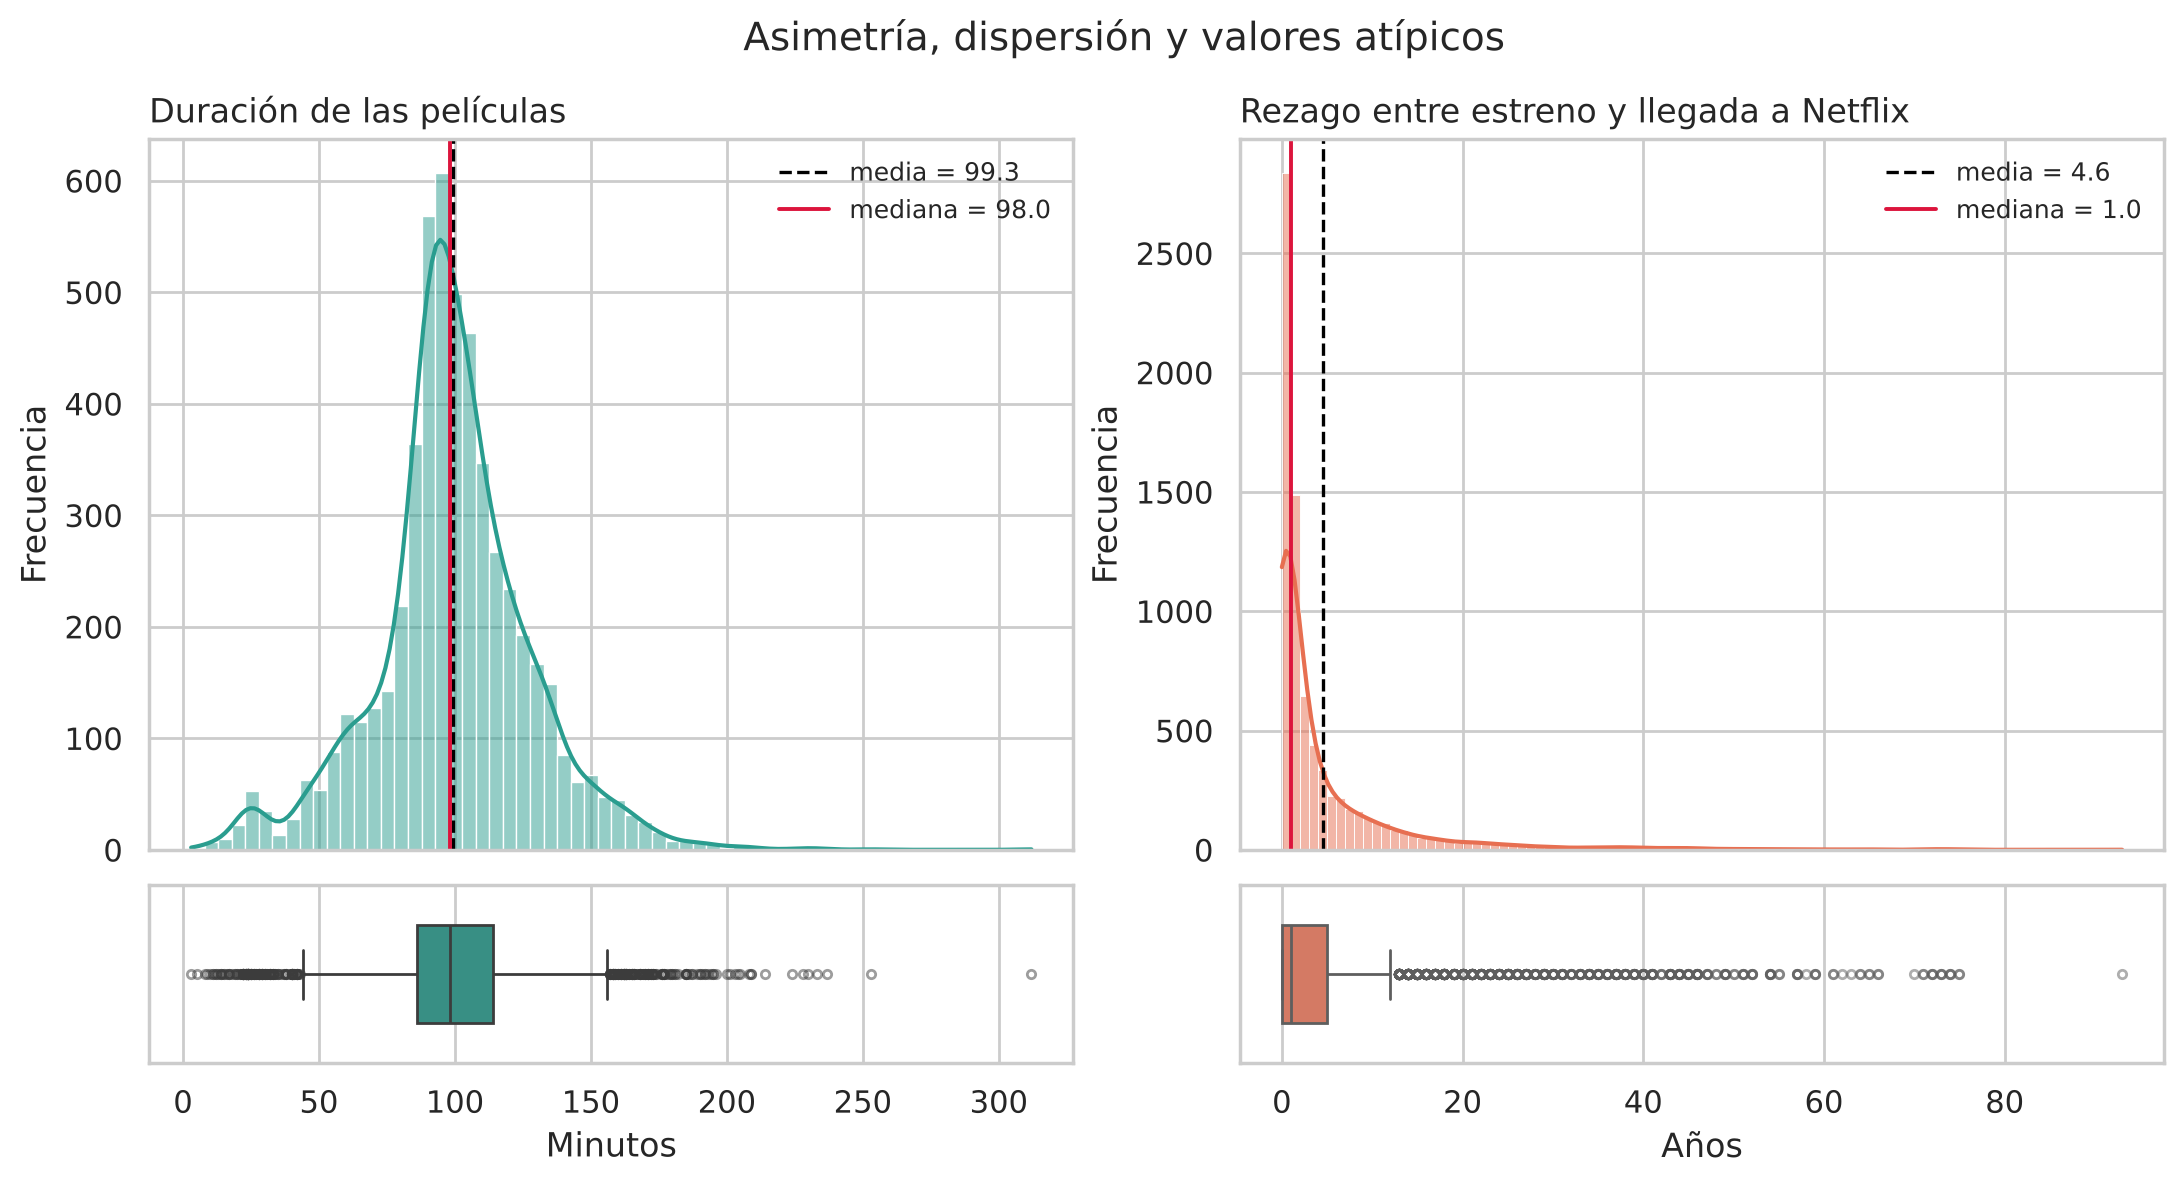

In [12]:
# =====================================================================
# 6. DISTRIBUCIONES: histograma + boxplot (Seaborn / Matplotlib)
# =====================================================================
def panel_dist(ax_h, ax_b, serie, titulo, xlabel, color, binwidth):
    """Histograma con KDE arriba y boxplot horizontal abajo, compartiendo el eje x."""
    sns.histplot(serie, binwidth=binwidth, kde=True, color=color, edgecolor="white", ax=ax_h)
    ax_h.axvline(serie.mean(), color="black", ls="--", lw=1.2, label=f"media = {serie.mean():.1f}")
    ax_h.axvline(serie.median(), color="crimson", ls="-", lw=1.4, label=f"mediana = {serie.median():.1f}")
    ax_h.set_title(titulo, fontsize=12, loc="left")
    ax_h.set_ylabel("Frecuencia"); ax_h.set_xlabel("")
    ax_h.legend(frameon=False, fontsize=9)
    plt.setp(ax_h.get_xticklabels(), visible=False)
    # Boxplot: whis=1.5 marca como atípico todo lo que pase de Q1-1.5·IQR o Q3+1.5·IQR
    sns.boxplot(x=serie, color=color, width=0.55, whis=1.5,
                flierprops=dict(marker="o", markersize=3, alpha=0.5), ax=ax_b)
    ax_b.set_xlabel(xlabel); ax_b.set_yticks([])

peliculas = df["minutos"].dropna()
rezago = df["rezago"].dropna()

fig_d = plt.figure(figsize=(13, 6))
gs = fig_d.add_gridspec(2, 2, height_ratios=[4, 1], hspace=0.08, wspace=0.18)
panel_dist(fig_d.add_subplot(gs[0, 0]), fig_d.add_subplot(gs[1, 0]),
           peliculas, "Duración de las películas", "Minutos", "#2a9d8f", 5)
panel_dist(fig_d.add_subplot(gs[0, 1]), fig_d.add_subplot(gs[1, 1]),
           rezago, "Rezago entre estreno y llegada a Netflix", "Años", "#e76f51", 1)
fig_d.suptitle("Asimetría, dispersión y valores atípicos", fontsize=14, y=0.98)
fig_d.savefig("figuras/03_distribuciones.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
# Tabla de estadísticos y regla de Tukey para valores atípicos
def resumen(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({
        "n": len(s), "media": s.mean(), "mediana": s.median(), "desv. est.": s.std(),
        "Q1": q1, "Q3": q3, "IQR": iqr, "asimetría": stats.skew(s), "curtosis (exceso)": stats.kurtosis(s),
        "límite inf.": lo, "límite sup.": hi,
        "atípicos": int(((s < lo) | (s > hi)).sum()), "% atípicos": 100 * ((s < lo) | (s > hi)).mean(),
        "máximo": s.max(), "mínimo": s.min(),
    })
tabla_dist = pd.DataFrame({"Duración (min)": resumen(peliculas), "Rezago (años)": resumen(rezago)}).round(2)
tabla_dist

,Duración (min),Rezago (años)
n,5377.00,7777.00
media,99.31,4.56
mediana,98.00,1.00
desv. est.,28.53,8.73
Q1,86.00,0.00
Q3,114.00,5.00
IQR,28.00,5.00
asimetría,0.19,3.68
curtosis (exceso),2.04,17.60
límite inf.,44.00,-7.50


### Interpretación de las distribuciones

**Duración de películas: casi simétrica con colas pesadas.** La media (99.3 min) y la mediana (98) casi coinciden, y la asimetría es de apenas 0.19. Sin embargo, la curtosis en exceso vale 2.04, es decir, las colas son más pesadas que las de una normal. El IQR va de 86 a 114 minutos (28 min de ancho) y los límites de Tukey quedan en 44 y 156. Fuera de ellos hay 337 películas (6.3%), tanto cortas como muy largas; la más extensa dura 312 minutos y la más corta, 3.

Hay un detalle que solo muestra el histograma: una pequeña joroba cerca de los 25 a 45 minutos. El boxplot no la registra, porque un resumen de cinco números no detecta multimodalidad. Mi hipótesis es que se trata de especiales y cortometrajes, pero el dataset no trae información para confirmarlo.

**Rezago: fuertemente asimétrica a la derecha.** Aquí media y mediana se separan mucho: 4.6 años contra 1.0. La asimetría es 3.68 y la curtosis en exceso 17.6. El primer cuartil es 0, lo que significa que al menos una cuarta parte de los títulos entra a Netflix el mismo año de su estreno. El límite superior de Tukey es 12.5 años y 812 títulos (10.4%) lo superan; el máximo es 93 años, es decir, material de catálogo histórico.

El límite inferior de Tukey (-7.5) queda por debajo del mínimo posible, así que en este lado no puede haber atípicos. Esa es una limitación estructural de la regla en variables acotadas en cero.

**Qué implica para el análisis.** En el rezago la media engaña: describe a muy pocos títulos, y la mediana es el resumen honesto. Los 812 atípicos corresponden a catálogo antiguo y no a errores de captura; borrarlos distorsionaría el resultado. Si hubiera que comparar grupos, convendría usar escala logarítmica o `log1p` para que la cola no aplaste la zona donde está el 75% de los datos.

**Principios de codificación.** Ambas variables se codifican con posición sobre una escala común, el canal más preciso según Cleveland y McGill. Compartir el eje x entre histograma y boxplot permite alinear forma y resumen sin esfuerzo. Los dos paneles usan colores distintos solo para diferenciar variables, no para codificar valores.

## Paso 2.4. Modelos temporales: serie de tiempo interactiva

**Pregunta:** ¿cómo evolucionó el ritmo de incorporación de títulos, hay estacionalidad y hubo algún cambio brusco?

**Datos.** Se cuentan los títulos por mes de `date_added`, separados en películas y series. El período es 2015-01 a 2020-12: antes de 2015 hay muy pocas altas con fecha, y enero de 2021 está incompleto (el dataset termina el día 16).

**Componentes del análisis:**

- **Tendencia.** Media móvil centrada de 12 meses, que elimina el ciclo anual.
- **Estacionalidad.** Cociente entre cada mes y su media móvil, promediado por mes calendario (un índice de 1.00 equivale al nivel típico del año).
- **Ruptura.** Regresión lineal en dos tramos. Se prueba cada mes candidato como punto de corte y se conserva el que minimiza la suma de errores cuadrados. Se exige un margen de 12 meses a cada lado.

**Interactividad.** Hover unificado en el eje x, selector de rango (1 año, 3 años, todo) y minigráfico inferior (*range slider*) para acotar la ventana. Es la técnica de enfoque + contexto: el detalle se explora sin perder la vista global.

In [14]:
# =====================================================================
# 7. MODELOS TEMPORALES: serie interactiva con Plotly
# =====================================================================
# Se usa 2015-01 a 2020-12: antes de 2015 hay muy pocas altas con fecha y enero de 2021 está incompleto
# (el dataset termina el 16 de enero de 2021).
mensual = (df.dropna(subset=["date_added"]).set_index("date_added")
             .groupby([pd.Grouper(freq="MS"), "type"]).size().unstack(fill_value=0))
mensual = mensual.loc["2015-01":"2020-12"]
mensual["Total"] = mensual.sum(axis=1)
mensual["Media móvil 12m"] = mensual["Total"].rolling(12, center=True).mean()

# --- Punto de ruptura: regresión lineal en dos tramos, se prueba cada mes candidato
#     y se conserva el que minimiza la suma de errores cuadrados (SSE).
y = mensual["Total"].values.astype(float); x = np.arange(len(y))
def sse_ajuste(xs, ys):
    p = np.polyfit(xs, ys, 1)
    return ((ys - np.polyval(p, xs)) ** 2).sum(), p
sse_uno, _ = sse_ajuste(x, y)
mejor = min(range(12, len(y) - 12),
            key=lambda k: sse_ajuste(x[:k], y[:k])[0] + sse_ajuste(x[k:], y[k:])[0])
sse_dos = sse_ajuste(x[:mejor], y[:mejor])[0] + sse_ajuste(x[mejor:], y[mejor:])[0]
fecha_ruptura = mensual.index[mejor]
p1 = sse_ajuste(x[:mejor], y[:mejor])[1]; p2 = sse_ajuste(x[mejor:], y[mejor:])[1]
print(f"Ruptura estimada: {fecha_ruptura:%Y-%m} | SSE un tramo = {sse_uno:,.0f} | "
      f"SSE dos tramos = {sse_dos:,.0f} ({100*(1-sse_dos/sse_uno):.0f}% menos)")
print(f"Pendiente antes: {p1[0]:+.1f} títulos/mes por mes | después: {p2[0]:+.1f}")

Ruptura estimada: 2019-10 | SSE un tramo = 66,567 | SSE dos tramos = 44,002 (34% menos)
Pendiente antes: +3.5 títulos/mes por mes | después: -4.5


In [15]:
fig_s = go.Figure()
fig_s.add_trace(go.Scatter(x=mensual.index, y=mensual["Movie"], name="Películas",
                           mode="lines", line=dict(color="#2a9d8f", width=1.5)))
fig_s.add_trace(go.Scatter(x=mensual.index, y=mensual["TV Show"], name="Series",
                           mode="lines", line=dict(color="#e76f51", width=1.5)))
fig_s.add_trace(go.Scatter(x=mensual.index, y=mensual["Total"], name="Total mensual",
                           mode="lines+markers", line=dict(color="#264653", width=2.2), marker=dict(size=4)))
fig_s.add_trace(go.Scatter(x=mensual.index, y=mensual["Media móvil 12m"], name="Media móvil 12 meses",
                           mode="lines", line=dict(color="black", width=3, dash="dash")))
# Ajuste lineal de cada tramo para visualizar el cambio de pendiente
fig_s.add_trace(go.Scatter(x=mensual.index[:mejor], y=np.polyval(p1, x[:mejor]), name="Tendencia antes",
                           mode="lines", line=dict(color="gray", width=2, dash="dot")))
fig_s.add_trace(go.Scatter(x=mensual.index[mejor:], y=np.polyval(p2, x[mejor:]), name="Tendencia después",
                           mode="lines", line=dict(color="gray", width=2, dash="dot"), showlegend=False))
fig_s.add_vline(x=fecha_ruptura, line=dict(color="crimson", dash="dash"),
                annotation_text=f"Ruptura estimada ({fecha_ruptura:%b %Y})", annotation_position="top left")
fig_s.add_vline(x=pd.Timestamp("2020-03-11"), line=dict(color="steelblue", dash="dot"),
                annotation_text="OMS declara la pandemia", annotation_position="top right")
fig_s.update_layout(
    title="Títulos añadidos al catálogo por mes (2015-2020)", width=1100, height=560,
    hovermode="x unified", template="plotly_white",
    yaxis_title="Títulos añadidos", xaxis_title=None,
    legend=dict(orientation="h", y=-0.28),
    xaxis=dict(rangeslider=dict(visible=True, thickness=0.07),
               rangeselector=dict(buttons=[
                   dict(count=1, label="1 año", step="year", stepmode="backward"),
                   dict(count=3, label="3 años", step="year", stepmode="backward"),
                   dict(step="all", label="Todo")])),
)
fig_s.write_html("figuras/04_serie_tiempo.html")
fig_s.show()

In [16]:
# Estacionalidad: cociente entre cada mes y la media móvil centrada de 12 meses, promediado por mes calendario
razon = (mensual["Total"] / mensual["Media móvil 12m"]).dropna()
indice_estacional = razon.groupby(razon.index.month).mean()
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig_e = go.Figure(go.Bar(
    x=meses, y=indice_estacional.values,
    marker_color=["#e76f51" if v > 1.05 else "#8ab6b1" if v < 0.95 else "#bdbdbd" for v in indice_estacional.values],
    text=[f"{v:.2f}" for v in indice_estacional.values], textposition="outside",
    hovertemplate="%{x}: %{y:.2f} veces el nivel anual<extra></extra>"))
fig_e.add_hline(y=1, line=dict(color="black", dash="dash"))
fig_e.update_layout(title="Índice estacional (1.00 = nivel medio del año)", width=900, height=420,
                    template="plotly_white", yaxis=dict(range=[0, 1.7], title="Índice"))
fig_e.write_html("figuras/05_estacionalidad.html")
fig_e.show()

print("Totales anuales:")
print(mensual["Total"].resample("YS").sum().rename(lambda d: d.year).to_string())
print("\nMes con más altas:", mensual["Total"].idxmax().strftime("%Y-%m"), "->", int(mensual["Total"].max()))
print("Meses con índice > 1.05:", [meses[m - 1] for m, v in indice_estacional.items() if v > 1.05])

Totales anuales:
date_added
2015      88
2016     443
2017    1225
2018    1685
2019    2153
2020    2009

Mes con más altas: 2019-11 -> 272
Meses con índice > 1.05: ['Ene', 'Mar', 'Oct', 'Dic']


### Interpretación de la serie

**Tendencia.** Las altas anuales crecen de 88 (2015) a 443 (2016), 1,225 (2017), 1,685 (2018) y 2,153 (2019), para bajar a 2,009 en 2020. La media móvil sube casi en línea recta hasta mediados de 2019 y después se aplana en torno a 180 títulos por mes. El máximo mensual es noviembre de 2019, con 272 títulos.

**Ruptura.** El método ubica el quiebre en octubre de 2019. Antes, el volumen mensual crecía unos 3.5 títulos cada mes; después cae unos 4.5 cada mes. Dos rectas reducen el error cuadrático un 34% respecto de una sola (de 66,567 a 44,002). Conviene leerlo con cuidado: el punto queda a solo 15 meses del final de la serie, la reducción de error no está acompañada de una prueba formal de significancia, y el quiebre coincide con el pico de noviembre de 2019, que por sí solo ya pesa en el ajuste.

**El efecto de 2020.** La caída de 2019 a 2020 viene de las películas, que bajan de 1,497 a 1,312 altas (-12%), mientras que las series suben de 656 a 697 (+6%). La marca de la pandemia (11 de marzo de 2020) cae después de febrero, el mes más bajo del período reciente (117 títulos), de modo que la caída empezó antes. No hay forma de atribuirla a la pandemia con estos datos: el análisis solo muestra coincidencia temporal.

**Estacionalidad.** Enero (1.43), diciembre (1.29), marzo (1.17) y octubre (1.14) están por encima del nivel anual. Mayo y junio (0.82) son los más bajos. Esto describe cuándo se registran las altas, y no cuándo se consume: refleja el calendario de lanzamientos y no tiene por qué relacionarse con la demanda. El índice se apoya en unos cinco ciclos anuales y la tendencia creciente lo sesga ligeramente, de modo que sirve como orden de magnitud, no como valor exacto.

**Principios de codificación.** La posición sobre ejes comunes es el canal de mayor precisión y permite comparar directamente películas, series y total. Las líneas conectan puntos consecutivos y aprovechan el principio gestáltico de continuidad. La línea discontinua gruesa de la media móvil se separa del ruido mensual por grosor y trazo. Las anotaciones directas (ruptura, pandemia) evitan que el lector deba buscar en una leyenda.

## Apéndice. Versiones estáticas para el informe

Plotly necesita un navegador instalado (la librería `kaleido`) para exportar PNG, algo que no todos los equipos tienen. Para que el notebook se ejecute completo en cualquier entorno, la siguiente celda redibuja el treemap, el grafo y la serie con Matplotlib y los mismos datos, y los guarda en `figuras/`. Son las imágenes que aparecen en el informe PDF. Las versiones interactivas originales se guardan como HTML en la misma carpeta.

In [17]:
# =====================================================================
# 8. Versiones estáticas (PNG) para el informe PDF
# =====================================================================
# Plotly necesita un navegador (kaleido) para exportar PNG. Para que el notebook se ejecute en
# cualquier equipo, las figuras interactivas se redibujan aquí con Matplotlib, con los mismos datos.
import matplotlib.colors as mcolors

# 8.1 Treemap jerárquico con squarify: se reparte el área nivel por nivel (tipo > público > género)
norm = mcolors.Normalize(vmin=tm["anio_prom"].min(), vmax=tm["anio_prom"].max())
cmap = plt.get_cmap("viridis_r")
NIVELES = ["type", "publico", "genero_tm"]
ENCABEZADO = [3.0, 2.8, 0.0]          # alto reservado para el rótulo de cada nivel

def hojas_jerarquicas(tabla, prof, x, y, dx, dy, acum, ruta=()):
    """Subdivide el rectángulo con squarify en cada nivel y devuelve todos los rectángulos."""
    suma = tabla.groupby(NIVELES[prof])["titulos"].sum().sort_values(ascending=False)
    rects = squarify.squarify(squarify.normalize_sizes(suma.values, dx, dy), x, y, dx, dy)
    for (nombre, total), r in zip(suma.items(), rects):
        sub = tabla[tabla[NIVELES[prof]] == nombre]
        reg = dict(prof=prof, nombre=nombre, total=total, ruta=ruta + (nombre,), **r)
        if prof + 1 == len(NIVELES):
            reg["anio"] = sub["anio_prom"].iloc[0]          # cada hoja es una sola fila de tm
        acum.append(reg)
        if prof + 1 < len(NIVELES):
            m, h = 0.25, ENCABEZADO[prof]
            hojas_jerarquicas(sub, prof + 1, r["x"] + m, r["y"] + m + h,
                              r["dx"] - 2 * m, r["dy"] - 2 * m - h, acum, ruta + (nombre,))
    return acum

W, H = 100, 62
rects = hojas_jerarquicas(tm, 0, 0, 0, W, H, [])
fig, ax = plt.subplots(figsize=(13, 8))
for r in (q for q in rects if q["prof"] == 2):               # hojas: color = año de estreno promedio
    ax.add_patch(plt.Rectangle((r["x"], r["y"]), r["dx"], r["dy"],
                               facecolor=cmap(norm(r["anio"])), edgecolor="white", lw=1))
    if r["dx"] > 0.62 * len(r["nombre"]) + 1.5 and r["dy"] > 3.6:   # solo se rotula si el texto cabe
        ax.text(r["x"] + r["dx"] / 2, r["y"] + r["dy"] / 2, f"{r['nombre']}\n{r['total']:,}",
                ha="center", va="center", fontsize=7.5,
                color="white" if norm(r["anio"]) > 0.35 else "black")
for r in rects:                                           # contornos y rótulos de los niveles superiores
    if r["prof"] == 0:
        ax.add_patch(plt.Rectangle((r["x"], r["y"]), r["dx"], r["dy"], fill=False, edgecolor="black", lw=3))
        ax.text(r["x"] + 0.8, r["y"] + 1.5, f"{'PELÍCULAS' if r['nombre'] == 'Movie' else 'SERIES'}  ({r['total']:,})",
                va="center", fontsize=11, weight="bold", color="black")
    elif r["prof"] == 1:
        ax.add_patch(plt.Rectangle((r["x"], r["y"]), r["dx"], r["dy"], fill=False, edgecolor="white", lw=2.2))
        if r["total"] >= 20:                                 # los grupos minúsculos no llevan rótulo
            una_linea = f"{r['nombre']} ({r['total']:,})"
            texto = una_linea if r["dx"] > 0.6 * len(una_linea) + 1 else f"{r['nombre']}\n({r['total']:,})"
            if r["dx"] > 0.6 * max(len(p) for p in texto.split("\n")) + 1:
                ax.text(r["x"] + 0.6, r["y"] + 0.5, texto, va="top", fontsize=8, color="black")
ax.set_xlim(0, W); ax.set_ylim(0, H); ax.invert_yaxis(); ax.axis("off")
ax.set_title("Treemap: tipo > público > género (área = títulos, color = año de estreno promedio)", loc="left")
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax, shrink=0.6, label="Año de estreno promedio")
fig.savefig("figuras/s01_treemap.png", dpi=200, bbox_inches="tight"); plt.close(fig)

# 8.2 Grafo
fig, ax = plt.subplots(figsize=(13, 8.5))
for u, v, w in G.edges(data="weight"):
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#555",
            lw=0.5 if w == 3 else 1.2 if w < 6 else 2.4, alpha=0.2 if w == 3 else 0.4 if w < 6 else 0.7, zorder=1)
ax.scatter([pos[n][0] for n in G], [pos[n][1] for n in G], s=[20 + 9 * grado[n] for n in G],
           c=[paleta[com_de[n] % len(paleta)] for n in G], edgecolor="white", linewidth=0.6, zorder=2)
for n in nombres_top:
    ax.annotate(n, pos[n], xytext=(0, 7), textcoords="offset points", ha="center", fontsize=7.5, zorder=3,
                bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.75))
ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"Co-ocurrencia de actores: {len(G)} nodos, {G.number_of_edges()} aristas, {len(comunidades)} comunidades", loc="left")
fig.savefig("figuras/s02_grafo.png", dpi=200, bbox_inches="tight"); plt.close(fig)

# 8.3 Serie de tiempo + estacionalidad
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw=dict(width_ratios=[2.3, 1]))
a1.plot(mensual.index, mensual["Movie"], color="#2a9d8f", lw=1.2, label="Películas")
a1.plot(mensual.index, mensual["TV Show"], color="#e76f51", lw=1.2, label="Series")
a1.plot(mensual.index, mensual["Total"], color="#264653", lw=2, label="Total")
a1.plot(mensual.index, mensual["Media móvil 12m"], color="black", ls="--", lw=2.4, label="Media móvil 12m")
a1.axvline(fecha_ruptura, color="crimson", ls="--"); a1.text(fecha_ruptura, a1.get_ylim()[1] * 0.97, f" ruptura {fecha_ruptura:%b %Y}", color="crimson", va="top", fontsize=9)
a1.axvline(pd.Timestamp("2020-03-11"), color="steelblue", ls=":"); a1.text(pd.Timestamp("2020-03-11"), a1.get_ylim()[1] * 0.85, " pandemia", color="steelblue", fontsize=9)
a1.set_title("Títulos añadidos por mes", loc="left"); a1.legend(frameon=False, fontsize=8, loc="upper left")
a2.bar(meses, indice_estacional.values, color=["#e76f51" if v > 1.05 else "#8ab6b1" if v < 0.95 else "#bdbdbd" for v in indice_estacional.values])
a2.axhline(1, color="black", ls="--", lw=1); a2.set_title("Índice estacional", loc="left"); a2.tick_params(axis="x", labelsize=8)
fig.tight_layout(); fig.savefig("figuras/s04_serie.png", dpi=200, bbox_inches="tight"); plt.close(fig)
print("Figuras estáticas guardadas en ./figuras")

Figuras estáticas guardadas en ./figuras


## Conclusiones y límites

Los cuatro gráficos responden preguntas distintas sobre el mismo catálogo. El treemap muestra que las series son más recientes y más infantiles que las películas. El grafo muestra que la colaboración entre actores forma islas cerradas (anime japonés, Bollywood, animación infantil) y no una red global. El panel de distribuciones deja claro que el rezago exige mediana y no media, y la serie de tiempo muestra un crecimiento sostenido que se frena hacia finales de 2019.

Tres límites afectan las conclusiones: el catálogo es una captura del momento y no incluye lo retirado, los actores se identifican solo por nombre, y la serie termina en enero de 2021, demasiado pronto para saber si la desaceleración fue pasajera.